In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('/content/game_dataset.csv')

In [4]:
df.head()

,Game_ID,Game_Name,Genre,Platform,Release_Year,Global_Sales,User_Rating,Active_Players
0,G0001,Warrior Galaxy,Adventure,Switch,2002,28.62,4.8,95.7
1,G0002,Legend Quest,Action,Mobile,2019,24.17,5.4,50.9
2,G0003,Empire Battle,Adventure,PlayStation,2016,37.46,9.6,50.5
3,G0004,Shadow Rise,Strategy,PlayStation,2019,17.05,8.9,82.2
4,G0005,Quest Arena,Adventure,Switch,2020,31.26,1.3,41.8


In [5]:
df.tail()

,Game_ID,Game_Name,Genre,Platform,Release_Year,Global_Sales,User_Rating,Active_Players
1995,G1996,Battle Fury,RPG,Xbox,2017,10.57,6.5,17.1
1996,G1997,Battle Battle,Adventure,Xbox,2017,49.58,1.7,78.4
1997,G1998,Quest Fury,Racing,PC,2016,24.20,9.2,90.5
1998,G1999,Empire Warrior,RPG,PlayStation,2017,38.04,3.8,75.7
1999,G2000,Legend Fury,Adventure,Xbox,2004,10.25,2.8,62.5


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Game_ID         2000 non-null   object 
 1   Game_Name       2000 non-null   object 
 2   Genre           2000 non-null   object 
 3   Platform        2000 non-null   object 
 4   Release_Year    2000 non-null   int64  
 5   Global_Sales    2000 non-null   float64
 6   User_Rating     2000 non-null   float64
 7   Active_Players  2000 non-null   float64
dtypes: float64(3), int64(1), object(4)
memory usage: 125.1+ KB


In [7]:
df.isnull().sum()

,0
Game_ID,0
Game_Name,0
Genre,0
Platform,0
Release_Year,0
Global_Sales,0
User_Rating,0
Active_Players,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (2000, 8)


In [11]:
print("Duplicate Game_ID values:", df["Game_ID"].duplicated().sum())

Duplicate Game_ID values: 0


In [12]:
df.describe(include="all")

,Game_ID,Game_Name,Genre,Platform,Release_Year,Global_Sales,User_Rating,Active_Players
count,2000,2000,2000,2000,2000.000000,2000.000000,2000.000000,2000.000000
unique,2000,100,7,5,NaN,NaN,NaN,NaN
top,G1984,Warrior Empire,Racing,Switch,NaN,NaN,NaN,NaN
freq,1,31,320,412,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2012.239000,24.496655,5.476050,50.424100
std,NaN,NaN,NaN,NaN,7.378014,14.514006,2.562662,28.409096
min,NaN,NaN,NaN,NaN,2000.000000,0.130000,1.000000,0.600000
25%,NaN,NaN,NaN,NaN,2006.000000,11.660000,3.300000,25.900000
50%,NaN,NaN,NaN,NaN,2012.500000,24.325000,5.500000,50.900000
75%,NaN,NaN,NaN,NaN,2019.000000,37.292500,7.600000,74.900000


In [13]:
numerical_columns = [
    "Release_Year",
    "Global_Sales",
    "User_Rating",
    "Active_Players"
]

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of potential outliers:", len(outliers))


Column: Release_Year
Lower limit: 1986.5
Upper limit: 2038.5
Number of potential outliers: 0

Column: Global_Sales
Lower limit: -26.788749999999997
Upper limit: 75.74125
Number of potential outliers: 0

Column: User_Rating
Lower limit: -3.1499999999999995
Upper limit: 14.049999999999999
Number of potential outliers: 0

Column: Active_Players
Lower limit: -47.600000000000016
Upper limit: 148.40000000000003
Number of potential outliers: 0


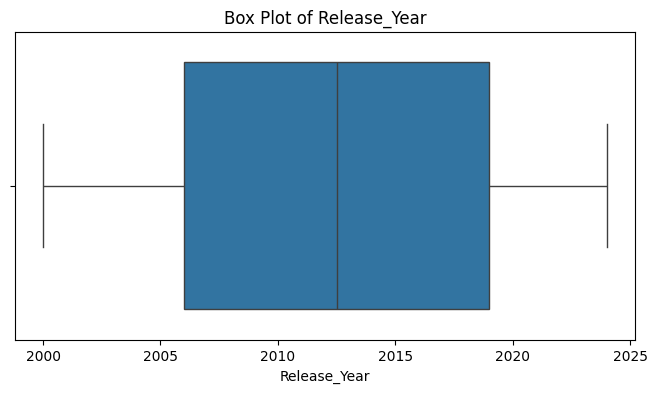

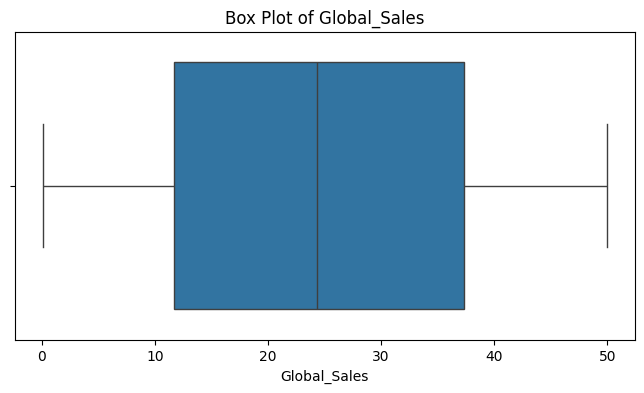

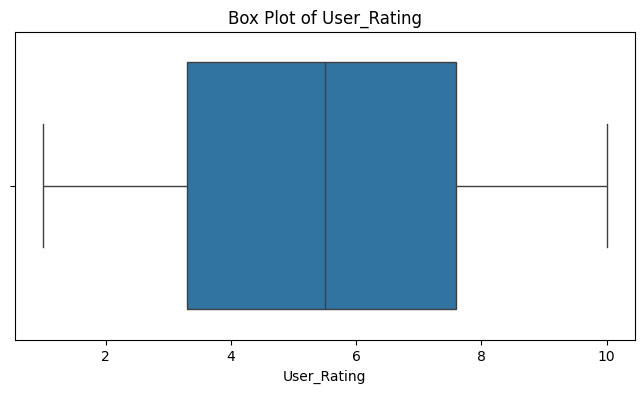

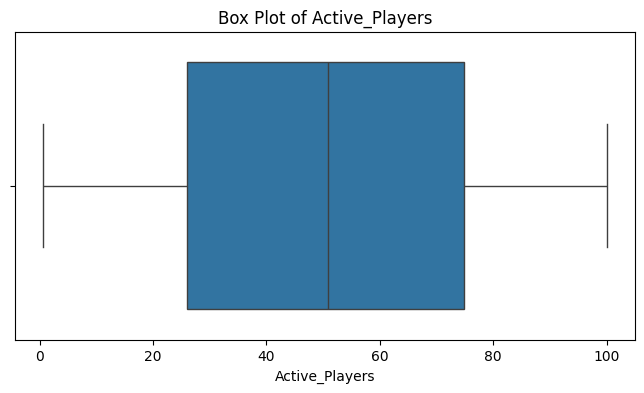

In [14]:
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=column)

    plt.title(f"Box Plot of {column}")

    plt.show()

In [22]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



In [23]:

X = df[
    [
        "Release_Year",
        "User_Rating",
        "Active_Players",
        "Genre",
        "Platform"
    ]
]


y = df["Global_Sales"]



In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (1600, 5)
Testing input shape: (400, 5)
Training target shape: (1600,)
Testing target shape: (400,)


In [25]:

numerical_features = [
    "Release_Year",
    "User_Rating",
    "Active_Players"
]
categorical_features = [
    "Genre",
    "Platform"
]
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [26]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!
